# 02 · 감정 분류 결과 보기

`exercise.py --run`이 저장한 `outputs/02_sentiment/<실행이름>/`을 읽습니다. 모드 3개 × lr 3개, 9개 실행을 비교표로 보고, 모드별로 고른 실행을 분석합니다. 학습 코드는 여기에 두지 않습니다.

matplotlib 기본 글꼴에는 한글이 없으므로 그림 안의 글자는 영어로 씁니다.

In [1]:
import json
import runpy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, f1_score

ns = runpy.run_path("../learning/02_sentiment/exercise.py")  # exercise.py의 상수·함수를 불러옵니다
out_dir = ns["OUTPUT_DIR"]
pd.set_option("display.max_colwidth", None)  # 문장이 잘리지 않게
sorted(p.name for p in out_dir.iterdir() if p.is_dir())  # 저장된 실행 목록

/home/minwoo/Develop/model-finetuning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['frozen_lr1e-03_seed42',
 'frozen_lr3e-03_seed42',
 'frozen_lr3e-04_seed42',
 'full_lr1e-05_seed42',
 'full_lr2e-05_seed42',
 'full_lr5e-05_seed42',
 'lora_lr1e-03_seed42',
 'lora_lr1e-04_seed42',
 'lora_lr5e-04_seed42']

## 1. 실행 비교표 (validation)

모드마다 lr 3개 중 **validation** 정확도가 가장 높은 실행을 고릅니다. test는 고른 뒤 5절에서만 봅니다.
비용 열은 `results.md` 결과 표의 시간·최대 GPU 메모리 칸에 옮깁니다.

In [2]:
# TODO: out_dir 아래 모든 */metrics.json을 읽어 실행마다 한 줄인 표 runs(DataFrame)를 만드세요.
# 열: run, mode, lr, val_acc, val_f1, trainable_params, train_seconds, peak_gpu_mb  (test 열은 넣지 않습니다)
# 힌트: rows = [] → for path in sorted(out_dir.glob("*/metrics.json")): rows.append({"run": path.parent.name, ...})
#       → pd.DataFrame(rows).sort_values(["mode", "val_acc"], ascending=[True, False])
rows = []
for path in sorted(out_dir.glob("*/metrics.json")):
    with open(path, 'r') as f:
        metrics = json.load(f)
    rows.append({
        "run": path.parent.name,
        "mode": metrics['config']['model_kind'],
        "lr": metrics['config']['learning_rate'],
        "val_acc": metrics['validation']['accuracy'],
        "val_f1": metrics['validation']['macro_f1'],
        "trainable_params": metrics['cost']['trainable_params'],
        "train_seconds": metrics['cost']['run_time'],
        "peak_gpu_mb": metrics['cost']['max_gpu_memory'] / (1024**2)
    })

runs = pd.DataFrame(rows).sort_values(["mode", "val_acc"], ascending=[True, False])
runs

,run,mode,lr,val_acc,val_f1,trainable_params,train_seconds,peak_gpu_mb
1,frozen_lr3e-03_seed42,frozen,0.00300,0.850,0.847882,592130,4.320074,303.048828
0,frozen_lr1e-03_seed42,frozen,0.00100,0.848,0.845779,592130,4.337492,303.048828
2,frozen_lr3e-04_seed42,frozen,0.00030,0.844,0.842018,592130,4.307130,303.048828
5,full_lr5e-05_seed42,full,0.00005,0.908,0.907346,66955010,12.027572,1052.093262
4,full_lr2e-05_seed42,full,0.00002,0.886,0.884984,66955010,11.947758,1052.093262
3,full_lr1e-05_seed42,full,0.00001,0.872,0.871090,66955010,11.489998,1052.093262
6,lora_lr1e-03_seed42,lora,0.00100,0.890,0.889019,739586,9.519057,386.381836
8,lora_lr5e-04_seed42,lora,0.00050,0.882,0.881036,739586,9.524718,386.381836
7,lora_lr1e-04_seed42,lora,0.00010,0.864,0.863368,739586,9.072665,386.381836


In [3]:
# TODO: 위 표에서 모드별로 val_acc가 가장 높은 실행 이름을 적으세요. 아래 셀들이 이 이름을 씁니다.
BEST = {"frozen": "frozen_lr3e-03_seed42", "full": "full_lr5e-05_seed42", "lora": "lora_lr1e-03_seed42"}

## 2. 학습 곡선

세 모드의 loss를 한 그림에 겹칩니다. 어느 모드가 더 낮은 loss까지 내려가는지, 언제 평평해지는지 봅니다.

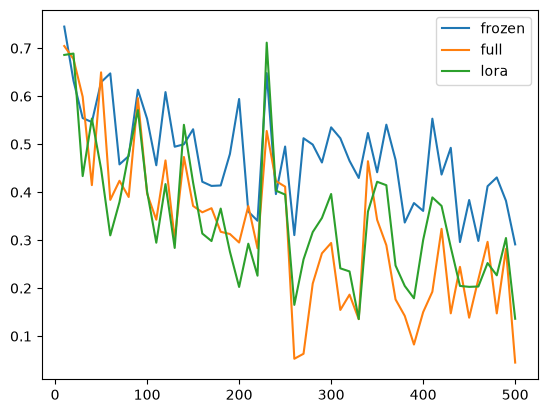

In [4]:
# TODO: BEST 세 실행의 metrics.json에서 log_history를 읽어 step별 loss를 한 그림에 겹쳐 그리고
#       out_dir / "train_loss_best.png"로 저장하세요. (여러 실행을 비교하는 그림이라 실행 폴더 밖에 저장)
# 힌트: log = [h for h in m["log_history"] if "loss" in h]  (마지막 요약 줄에는 "loss" 키가 없습니다)
#       → ax.plot([h["step"] for h in log], [h["loss"] for h in log], label=mode) → ax.legend()
fig, ax = plt.subplots()

for mode, name in BEST.items():
    with open(out_dir / name / "metrics.json") as f:
        metrics = json.load(f)
    log = [h for h in metrics["log_history"] if "loss" in h]
    ax.plot([h["step"] for h in log], [h["loss"] for h in log], label=mode)

ax.legend()
fig.show()
fig.savefig(out_dir / "train_loss_best.png")

## 3. 혼동행렬

이진 분류라 2×2입니다. 부정→긍정과 긍정→부정 중 어느 쪽 오류가 더 많은지 봅니다.

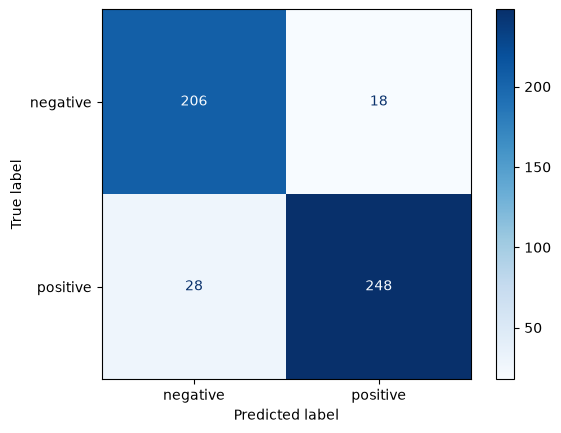

In [5]:
RUN = BEST["full"]  # 분석할 실행
SPLIT = "validation"  # test는 설정을 다 고른 뒤 마지막에만 봅니다
run_dir = out_dir / RUN

# TODO: run_dir / "metrics.json"은 metrics(dict)로, run_dir / "predictions.jsonl"은 한 줄씩 dict로 바꿔 predictions(list)로 읽으세요.
# Tip! `pathlib.Path` 객체는 `read_text()`를 통해 `with open ...` 없이 파일을 열어서 읽을 수 있음!
metrics = json.loads((run_dir / "metrics.json").read_text())
predictions = [json.loads(line) for line in (run_dir / "predictions.jsonl").read_text().splitlines()]

# TODO: metrics[SPLIT]의 혼동행렬을 그리고 run_dir / f"confusion_{SPLIT}.png"로 저장하세요.
# 힌트: ConfusionMatrixDisplay(np.array(...), display_labels=["negative", "positive"]).plot(cmap="Blues")
#       → disp.figure_.savefig(...)
disp = ConfusionMatrixDisplay(np.array(metrics[SPLIT]["confusion_matrix"]), display_labels=["negative", "positive"]).plot(cmap="Blues")
disp.figure_.savefig(run_dir / f"confusion_{SPLIT}.png")

## 4. 확신하고 틀린 문장 10개

`results.md` 실패 사례 칸에 옮길 근거입니다. 확률이 높은데 틀린 문장은 모델이 체계적으로 잘못 배운 신호일 수 있습니다.
SST-2 라벨 자체가 애매한 문장도 섞여 있으니 관찰과 원인 후보를 나눠 적으세요.

In [6]:
# TODO: predictions에서 SPLIT의 오답만 골라 prob가 큰 순서로 10개를 표로 보이세요.
# 힌트: wrong = [p for p in predictions if ...] → pd.DataFrame(wrong).sort_values("prob", ascending=False).head(10)
wrong = [
    p for p in predictions
    if (p['split'] == SPLIT) and (p['label'] != p['pred'])
]
pd.DataFrame(wrong).sort_values("prob", ascending=False).head(10)

,split,index,sentence,label,pred,prob
21,validation,47763,"the whole affair , true story or not , feels incredibly hokey",0,1,0.996351
40,validation,23529,often heartbreaking,0,1,0.996025
5,validation,66052,seamless,1,0,0.995205
37,validation,33152,", `` minority report '' astounds .",1,0,0.994252
9,validation,50182,"sentimental , hypocritical",0,1,0.993751
31,validation,19321,by the shadowy lighting,1,0,0.992352
4,validation,15377,"i still like moonlight mile , better judgment be damned .",1,0,0.992350
16,validation,58818,one of those ` alternate reality ',0,1,0.992315
14,validation,20390,", and unforgettable characters",1,0,0.992137
22,validation,49771,pays off,1,0,0.991629


## 5. 모드 비교 (test)

`results.md` 결과 표의 **95% CI** 칸과 표 아래 **paired bootstrap** 줄을 채웁니다. 01 노트북 4절과 같은 방법입니다.

- 정확도: 모델별 Wilson 구간 + 차이의 paired bootstrap
- Macro-F1: 정답 수로 나타낼 수 없어 Wilson 공식이 없습니다. 차이를 같은 bootstrap으로 구합니다

In [ ]:
from scipy.stats import binomtest

BASELINE, COMPARE = BEST["frozen"], BEST["full"]  # full vs lora도 이 두 줄만 바꿔 다시 실행합니다
COMPARE_SPLIT = "test"  # results.md 결과 표는 공식 validation 872문장 기준

# TODO: 두 실행의 predictions.jsonl에서 COMPARE_SPLIT 줄만 읽어 {idx: row} dict로 만드세요.
baseline = {}
compare = {}

with open(out_dir / BASELINE / "predictions.jsonl", "r") as f:
    for prediction in f.readlines():
        prediction = json.loads(prediction)
        if prediction['split'] == COMPARE_SPLIT:
            baseline[prediction['index']] = prediction

with open(out_dir / COMPARE / "predictions.jsonl", "r") as f:
    for prediction in f.readlines():
        prediction = json.loads(prediction)
        if prediction['split'] == COMPARE_SPLIT:
            compare[prediction['index']] = prediction

# 다 채운 뒤 주석을 풀어 확인: 두 실행이 같은 문장으로 평가됐는지 (paired 비교의 전제)
assert baseline.keys() == compare.keys()

# TODO: 같은 idx 순서로 label, baseline_pred, compare_pred numpy 배열 세 개를 만드세요.
keys = sorted(baseline)
label = np.array([baseline[key]['label'] for key in keys])
baseline_pred = np.array([baseline[key]['pred'] for key in keys])
compare_pred = np.array([compare[key]['pred'] for key in keys])

# TODO: 두 모델 정확도의 Wilson 95% 구간을 출력하세요 → results.md 결과 표의 95% CI 칸
# 힌트: binomtest(int((baseline_pred == label).sum()), len(label)).proportion_ci(method="wilson")
low, high = binomtest(int((baseline_pred == label).sum()), len(label)).proportion_ci(method="wilson")
print(f"Baseline CI: [{low=:.3f}, {high=:.3f}]")

Baseline CI: [low=0.839, high=0.885]


In [19]:
N_BOOTSTRAP = 10_000
rng = np.random.default_rng(0)  # seed를 고정해야 다시 실행해도 같은 구간이 나옵니다
n = len(keys)

# TODO: 같은 idx로 정확도 차이와 Macro-F1 차이(COMPARE − BASELINE)를 N_BOOTSTRAP번 계산해 acc_diffs, f1_diffs에 모으세요.
# 1. idx = rng.integers(0, n, size=n)
# 2. (compare_pred[idx] == label[idx]).mean() - (baseline_pred[idx] == label[idx]).mean()
# 3. f1_score(label[idx], compare_pred[idx], average="macro") - f1_score(label[idx], baseline_pred[idx], average="macro")
# f1_score를 2만 번 부르므로 비교 한 번에 10초쯤 걸립니다.
acc_diffs = []
f1_diffs = []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n, size=n)
    acc_diff = [(compare_pred[idx] == label[idx]).mean() - (baseline_pred[idx] == label[idx]).mean()]
    f1_diff = [f1_score(label[idx], compare_pred[idx], average='macro') - f1_score(label[idx], baseline_pred[idx], average='macro')]

    acc_diffs.append(acc_diff)
    f1_diffs.append(f1_diff)
    

# TODO: 지표별로 실제 차이(원래 872문장 기준)와 np.percentile(..., [2.5, 97.5])를 출력하세요 → results.md 표 아래 줄
low, high = np.percentile(acc_diffs, [2.5, 97.5])
print(f"Acc Real Diff: {(compare_pred == label).mean() - (baseline_pred == label).mean()}")
print(f"Acc Boostrap: [{low:.3f}, {high:.3f}]")

low, high = np.percentile(f1_diffs, [2.5, 97.5])
print(f"F1 Real Diff: {f1_score(label, compare_pred, average='macro') - f1_score(label, baseline_pred, average='macro')}")
print(f"F1 Boostrap: [{low:.3f}, {high:.3f}]")

Acc Real Diff: -0.004587155963302725
Acc Boostrap: [-0.023, 0.013]
F1 Real Diff: -0.004557718417760315
F1 Boostrap: [-0.023, 0.013]
